Import thư viện và đặt số nút con, threshold

In [2]:
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

seed=42
branching_factor, threshold = 10, 0.5
columns = ["Grocery", "Milk"]

Thêm và đọc dữ liệu

In [3]:
data = pd.read_csv("data/wholesale_customers.csv")
example_data = pd.read_csv("data/minh_hoa_birch.csv")
print("Wholesale customers:", data.shape)
print(data.head())
print("\nMinh họa Birch:", example_data.shape)
print(example_data.head())
print("\nThống kê hai đặc trưng:")
print(data[columns].describe().round(2))

Wholesale customers: (440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185

Minh họa Birch: (20, 2)
   Grocery  Milk
0        1     2
1        1     4
2        2     3
3        2     2
4        5     8

Thống kê hai đặc trưng:
        Grocery      Milk
count    440.00    440.00
mean    7951.28   5796.27
std     9503.16   7380.38
min        3.00     55.00
25%     2153.00   1533.00
50%     4755.50   3627.00
75%    10655.75   7190.25
max    92780.00  73498.00


Tiền xử lý dữ liệu

In [4]:
def dem_loi(df):
    so = df[columns].apply(pd.to_numeric, errors="coerce")
    return [int(so.isna().any(axis=1).sum()), int(df.duplicated().sum()), int((so < 0).any(axis=1).sum())]

kiem_tra = pd.DataFrame({"Wholesale": dem_loi(data), "Ví dụ 20 điểm": dem_loi(example_data)},
                        index=["Giá trị thiếu hoặc sai định dạng", "Dòng trùng toàn bộ", "Giá trị âm (không hợp lệ)"])
display(kiem_tra)
assert kiem_tra.to_numpy().sum() == 0

raw_data = data[columns].to_numpy(float)
example_X = example_data[columns].to_numpy(float)

,Wholesale,Ví dụ 20 điểm
Giá trị thiếu hoặc sai định dạng,0,0
Dòng trùng toàn bộ,0,0
Giá trị âm (không hợp lệ),0,0


Bảng kiểm tra cho thấy cả hai tập dữ liệu không có giá trị thiếu hoặc sai định dạng, không có dòng trùng toàn bộ và không có giá trị âm. Vì vậy không cần bước làm sạch dữ liệu, hai cột Grocery và Milk được giữ nguyên để chuẩn hóa.

In [5]:
class StandardScaler:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        return self

    def transform(self, X):
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        return Z * self.scale_ + self.mean_

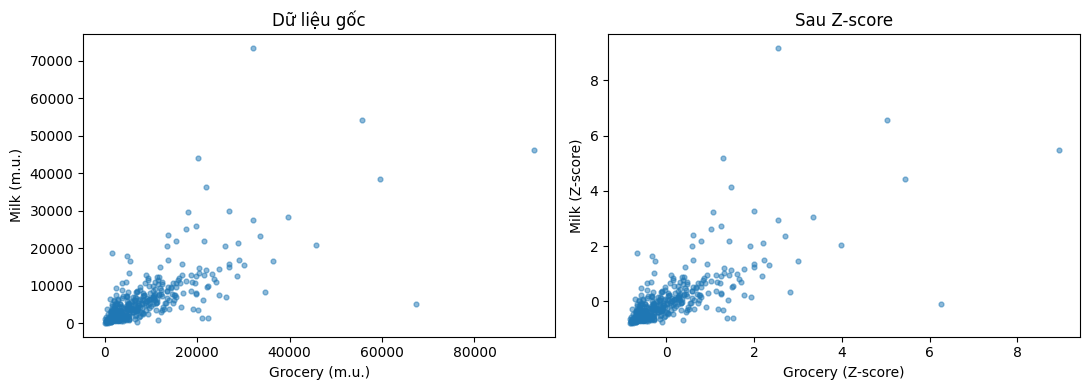

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(raw_data)
assert np.allclose(X.mean(axis=0), 0) and np.allclose(X.std(axis=0), 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(raw_data[:, 0], raw_data[:, 1], s=12, alpha=0.5)
axes[0].set(title="Dữ liệu gốc", xlabel=f"{columns[0]} (m.u.)", ylabel=f"{columns[1]} (m.u.)")
axes[1].scatter(X[:, 0], X[:, 1], s=12, alpha=0.5)
axes[1].set(title="Sau Z-score", xlabel=f"{columns[0]} (Z-score)", ylabel=f"{columns[1]} (Z-score)")
fig.tight_layout()
plt.show()